# AdaBoost: Boosting Stumps on Breast Cancer Data

**Family:** Supervised learning | **Level:** Intermediate | **Dataset:** `breast_cancer` | **Runs on:** CPU, about 1 minute(s)

Reweight the hard examples after each round and combine weak learners.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- How example weights shift towards mistakes
- How the weak learner votes are weighted
- Why AdaBoost is sensitive to label noise

**Prerequisites:**

- Decision tree notebook
- Logistic regression notebook

**Skills you will have afterwards:**

- Choose a hyperparameter on validation data
- Compare with a baseline
- Run a sensitivity experiment

## 2. Real-World Problem

**Context.** A single simple rule on one nucleus measurement is a weak classifier of tumours.

**The problem.** Combine many one-split rules into a strong malignancy classifier.

**Why it matters.** Boosting shows how weak signals can be combined into an accurate decision.

**Why machine learning.** No single feature separates the classes.

**Why this algorithm.** AdaBoost is the original boosting algorithm and has a clean theory.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### A Decision-Theoretic Generalization of On-Line Learning and an Application to Boosting

- **Type:** foundational paper
- **Authors:** Freund, Y. and Schapire, R. E.
- **Year and venue:** 1997, Journal of Computer and System Sciences 55(1):119-139
- **DOI or URL:** https://doi.org/10.1006/jcss.1997.1504
- **Verification:** Crossref 2026-11-17
- **Research objective:** Introduce AdaBoost and analyse its error.
- **Methodology:** Reweight training examples so that each weak learner focuses on earlier mistakes.
- **Dataset:** UCI datasets and an OCR task.
- **Main findings:** Boosting weak learners lowers training error quickly and often generalises well.
- **Limitations:** Sensitive to label noise and outliers.

### Greedy function approximation: A gradient boosting machine

- **Type:** foundational paper
- **Authors:** Friedman, J. H.
- **Year and venue:** 2001, The Annals of Statistics 29(5):1189-1232
- **DOI or URL:** https://doi.org/10.1214/aos/1013203451
- **Verification:** Crossref 2026-11-17
- **Research objective:** Cast boosting as gradient descent in function space.
- **Methodology:** Fit each new tree to the negative gradient of the loss, with shrinkage and optional subsampling.
- **Dataset:** Simulated data and a few real regression sets.
- **Main findings:** Boosted trees give accurate and robust regression and classification across loss functions.
- **Limitations:** Sequential training, sensitive to the learning rate and number of trees.

**Relationship to this notebook.** Freund and Schapire introduce AdaBoost and bound its error. Friedman later reads boosting as stage-wise optimisation of a loss. We use stumps on a different dataset from the paper. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Weights.** Start with $w_i = 1/n$.

**Round $m$.** Fit a weak learner $h_m$ with weighted error $\epsilon_m = \sum_i w_i \mathbb{1}[h_m(x_i) \ne y_i] / \sum_i w_i$. Set

$$\alpha_m = \tfrac12 \ln\frac{1-\epsilon_m}{\epsilon_m}, \qquad w_i \leftarrow w_i\, e^{-\alpha_m y_i h_m(x_i)}\ \text{then normalise}$$

with labels $y_i \in \{-1, +1\}$.

**Prediction.** $H(x) = \operatorname{sign}\big(\sum_m \alpha_m h_m(x)\big)$.

**Link to loss.** This minimises exponential loss $e^{-y f(x)}$ stage by stage.

**Limitations.** Exponential loss is sensitive to outliers and mislabelled rows.

## 5. Dataset Introduction

**Breast Cancer Wisconsin (Diagnostic)**, UCI, licence CC BY 4.0, DOI 10.24432/C5DW2B. 569 rows, 30 numeric features (mean, standard error and worst value of ten nucleus properties computed from digitised fine needle aspirate images). Target `malignant` (1 malignant, 0 benign). No missing values. Limits: one institution, small sample.

The table printed below the next cell comes from the dataset registry in `src/ml_lab/data/registry.py`. Licence terms belong to the data provider, not to this repository.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from ml_lab.data import load_dataset, missing_report
from ml_lab.preprocessing import split_three_way, build_preprocessor, make_model_pipeline, feature_names
from ml_lab.evaluation import evaluate_estimator, compare_models
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "adaboost"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("breast_cancer")
data = bundle.frame
TASK = bundle.task
TARGET = bundle.target
print("task:", TASK, "| target:", TARGET, "| shape:", data.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())
display(data.head())

task: classification | target: malignant | shape: (569, 31)


,source
title,Breast Cancer Wisconsin (Diagnostic)
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/17/breast+...
license,CC BY 4.0
doi,10.24432/C5DW2B
rows,569
features,30
limits,"Single institution, small sample, features com..."


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 6. Exploratory Data Analysis

We look at size, types, missing values, the target, feature distributions, correlation and outliers before any modelling. 

In [3]:
print("Rows and columns:", data.shape)
display(data.dtypes.value_counts().rename("columns by dtype").to_frame())
display(data.describe().T.round(3).head(20))
missing = missing_report(data)
print("Columns with missing values:", len(missing))
display(missing)
print("Duplicate rows:", int(data.duplicated().sum()))

Rows and columns: (569, 31)


,columns by dtype
float64,30
int64,1


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


Columns with missing values: 0


,missing,percent


Duplicate rows: 0


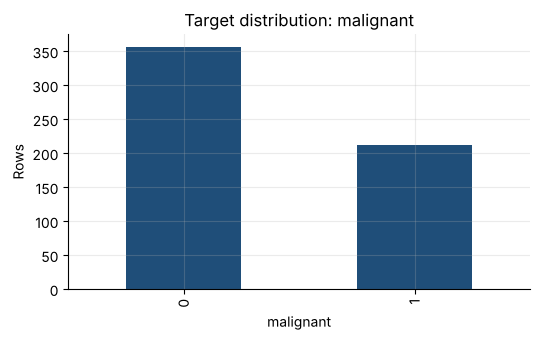

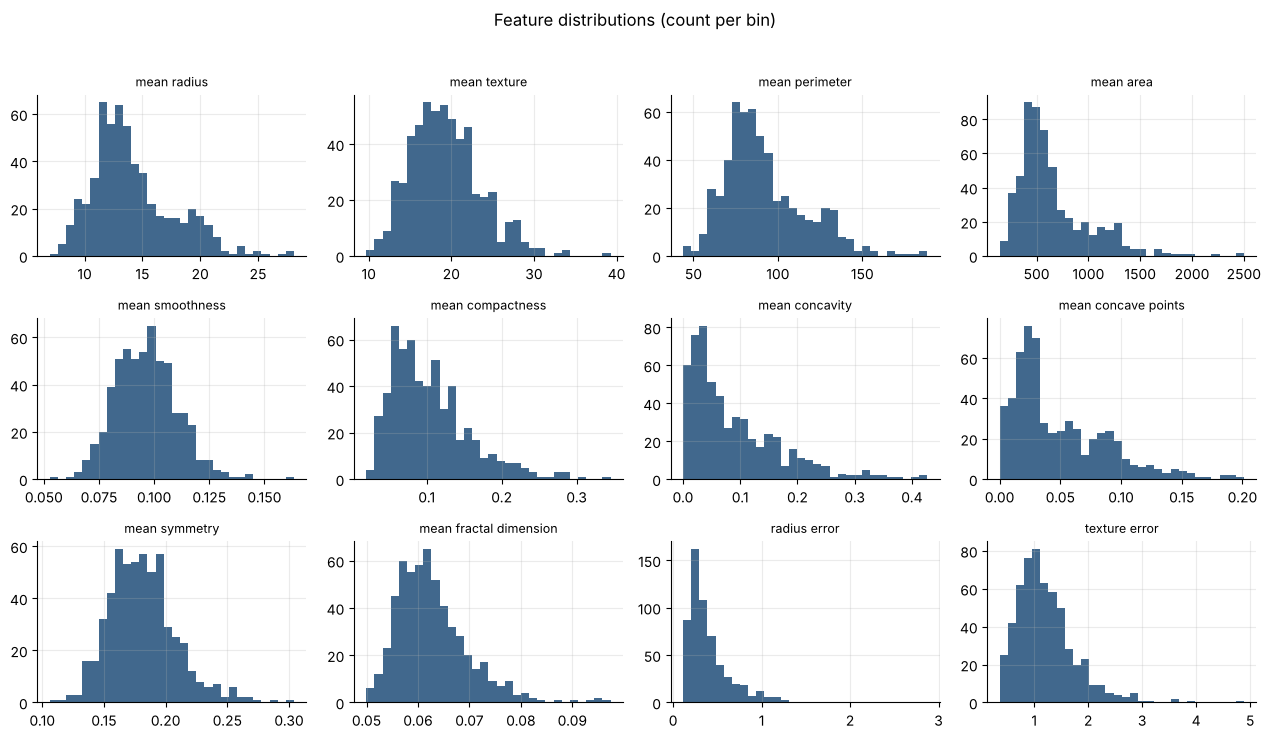

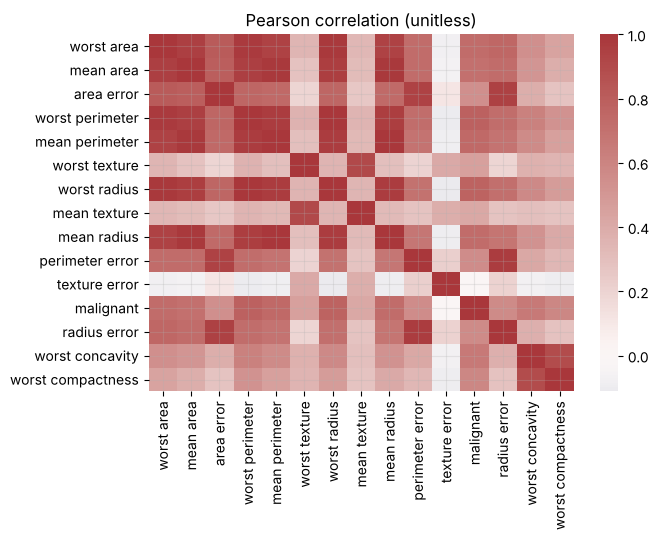

,feature,outliers,percent
0,area error,65,11.42
1,radius error,38,6.68
2,perimeter error,38,6.68
3,worst area,35,6.15
4,smoothness error,30,5.27
5,fractal dimension error,28,4.92
6,compactness error,28,4.92
7,symmetry error,27,4.75


In [4]:
fig = viz.plot_target(data[TARGET], TASK)
plt.show()
fig = viz.plot_distributions(data.drop(columns=[TARGET]))
plt.show()
fig = viz.plot_correlation(data)
plt.show()
display(viz.outlier_table(data.drop(columns=[TARGET])).head(8))

## 7. Data Preprocessing

Rules used here:

- Split first, then fit imputers, scalers and encoders on the training rows only. This prevents data leakage.
- The test set is touched once, at the end.
- Order inside the pipeline: impute, scale or encode, then model.


In [5]:

X, y = data.drop(columns=[TARGET]), data[TARGET]
X_train, X_val, X_test, y_train, y_val, y_test = split_three_way(X, y, task=TASK, seed=SEED)
print("train / validation / test rows:", len(X_train), len(X_val), len(X_test))
if TASK == "classification":
    split_rates = pd.DataFrame({"train": y_train.value_counts(normalize=True),
                                "validation": y_val.value_counts(normalize=True),
                                "test": y_test.value_counts(normalize=True)}).round(3)
    display(split_rates)
prep = build_preprocessor(X_train, scale=True, encode="onehot")
Xtr = prep.fit_transform(X_train)   # fit on train only
Xva, Xte = prep.transform(X_val), prep.transform(X_test)
print("transformed train shape:", Xtr.shape)

train / validation / test rows: 341 114 114


,train,validation,test
malignant,,,
0,0.628,0.623,0.632
1,0.372,0.377,0.368


transformed train shape: (341, 30)


## 8. Algorithm Implementation

### 8.1 Concept

Rows that earlier stumps misclassify get more weight, so the next stump must deal with them. Strong learners are built from weak ones.

### 8.2 Python implementation from scratch

We implement discrete AdaBoost with scikit-learn stumps as the weak learner.

validation accuracy after 60 stumps (scratch): 0.9561
sklearn validation accuracy: 0.9561


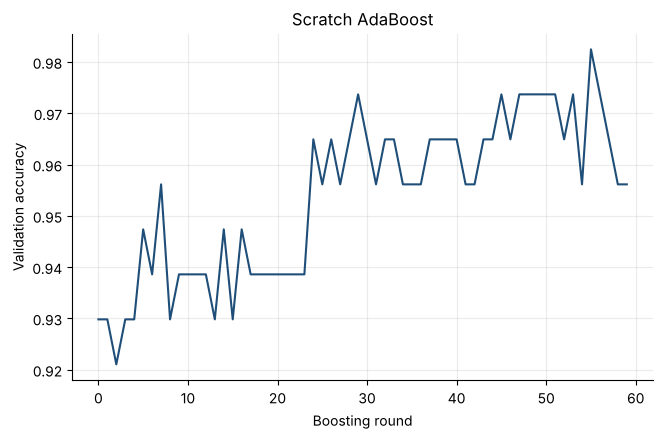

In [6]:
ypm = np.where(y_train.values == 1, 1, -1)
yvpm = np.where(y_val.values == 1, 1, -1)
w = np.ones(len(ypm)) / len(ypm)
stumps, alphas, val_acc = [], [], []
for m in range(60):
    stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(Xtr, ypm, sample_weight=w)
    pred = stump.predict(Xtr)
    err = w[pred != ypm].sum() / w.sum()
    a = 0.5 * np.log((1 - err) / (err + 1e-12))
    w = w * np.exp(-a * ypm * pred)
    w = w / w.sum()                              # renormalise
    stumps.append(stump); alphas.append(a)
    score = sum(al * s.predict(Xva) for al, s in zip(alphas, stumps))
    val_acc.append(np.mean(np.sign(score) == yvpm))
print("validation accuracy after 60 stumps (scratch):", round(val_acc[-1], 4))
ref = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=60, random_state=SEED).fit(Xtr, y_train)
print("sklearn validation accuracy:", round(float(ref.score(Xva, y_val)), 4))
plt.plot(val_acc); plt.xlabel("Boosting round"); plt.ylabel("Validation accuracy"); plt.title("Scratch AdaBoost"); plt.show()

### 8.3 Library implementation

The estimator is wrapped in a pipeline so imputation, scaling and encoding are fitted on training rows only.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `n_estimators` | Number of weak learners. |
| `learning_rate` | Shrinks each learner's vote. |
| `estimator` | Weak learner, stumps by default. |

## 9. Model Training

Procedure: fit on the training rows, choose one hyperparameter on the validation rows, refit on training plus validation, then evaluate once on the test rows. The random seed is fixed (`SEED = 42`). 

In [7]:
SELECT = "F1"
LOWER_IS_BETTER = False
SCORING = "f1"
SWEEP_PARAM = "model__n_estimators"
SWEEP_VALUES = [10, 25, 50, 100, 200, 400]

def build_pipeline():
    return make_model_pipeline(X_train, AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), random_state=SEED), scale=True, encode="onehot")

pipe = build_pipeline()
print(pipe.named_steps["model"])
rows = []
for value in SWEEP_VALUES:
    candidate = clone(pipe).set_params(**{SWEEP_PARAM: value}).fit(X_train, y_train)
    rows.append({SWEEP_PARAM: value, **evaluate_estimator(candidate, X_val, y_val, TASK)})
sweep = pd.DataFrame(rows).set_index(SWEEP_PARAM)
display(sweep[[c for c in [SELECT, "R2", "MAE", "Accuracy", "F1", "ROC_AUC", "PR_AUC"] if c in sweep.columns]].round(4))
best_value = sweep[SELECT].idxmin() if LOWER_IS_BETTER else sweep[SELECT].idxmax()
print("best", SWEEP_PARAM, "on validation:", best_value)
final_model = clone(pipe).set_params(**{SWEEP_PARAM: best_value})
X_trainval, y_trainval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
final_model.fit(X_trainval, y_trainval)   # refit before test
print("refit on train plus validation rows")

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                   random_state=42)


,F1,Accuracy,F1,ROC_AUC,PR_AUC
model__n_estimators,,,,,
10,0.9176,0.9386,0.9176,0.9885,0.9844
25,0.9535,0.9649,0.9535,0.9892,0.9879
50,0.9655,0.9737,0.9655,0.9938,0.9926
100,0.9425,0.9561,0.9425,0.9941,0.9924
200,0.9535,0.9649,0.9535,0.9954,0.9939
400,0.9535,0.9649,0.9535,0.9954,0.9939


best model__n_estimators on validation: 50
refit on train plus validation rows


## 10. Evaluation

Classification metrics: accuracy, precision, recall, F1, ROC-AUC and PR-AUC, plus the confusion matrix. With imbalanced classes accuracy alone misleads, so the model is chosen on F1 or PR-AUC as stated in the training cell.

A dummy model gives the floor every real model must beat.

In [8]:
baseline = DummyRegressor(strategy="mean") if TASK == "regression" else DummyClassifier(strategy="prior")
baseline = make_model_pipeline(X_train, baseline, scale=False).fit(X_trainval, y_trainval)
test_metrics = evaluate_estimator(final_model, X_test, y_test, TASK)
baseline_metrics = evaluate_estimator(baseline, X_test, y_test, TASK)
print("Test set, scored once after model choice")
display(compare_models({"baseline": baseline_metrics, "AdaBoostClassifier": test_metrics}))
cv = cross_validate(final_model, X_trainval, y_trainval, cv=5, scoring=SCORING, n_jobs=1)
cv_scores = cv["test_score"]
print(f"5-fold CV {SCORING}: mean {cv_scores.mean():.4f}, std {cv_scores.std(ddof=1):.4f}")
record = ExperimentRecord(notebook=NOTEBOOK_ID, family="supervised", algorithm="AdaBoostClassifier", dataset="breast_cancer",
                          task=TASK, seed=SEED, config={"param": SWEEP_PARAM, "value": str(best_value)},
                          metrics={k: float(v) for k, v in test_metrics.items()},
                          extra={"baseline": {k: float(v) for k, v in baseline_metrics.items()},
                                 "cv_mean": float(cv_scores.mean()), "cv_std": float(cv_scores.std(ddof=1)),
                                 "cv_scoring": SCORING, "select_metric": SELECT})
print("saved", record.save().name)

Test set, scored once after model choice


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
baseline,0.6316,0.0,0.0000,0.0000,0.5000,0.3684
AdaBoostClassifier,0.9825,1.0,0.9524,0.9756,0.9841,0.9845


5-fold CV f1: mean 0.9583, std 0.0193
saved adaboost.json


## 11. Visualization

All plots use the test rows unless the title says otherwise.

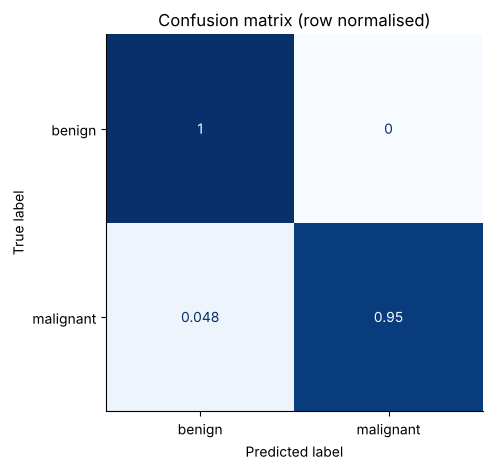

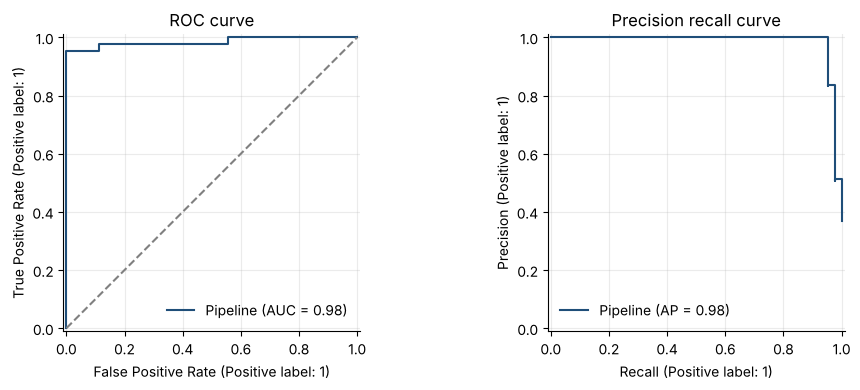

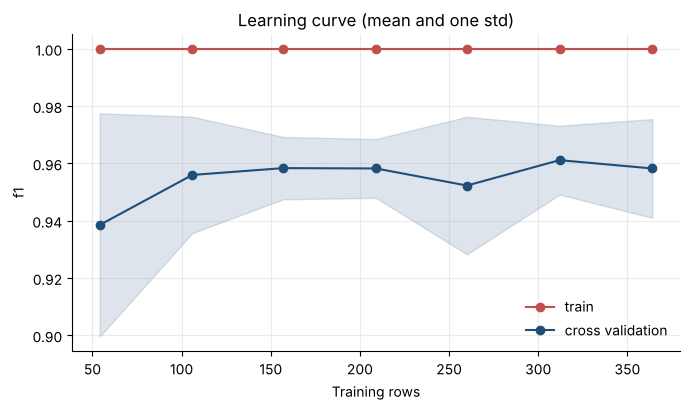

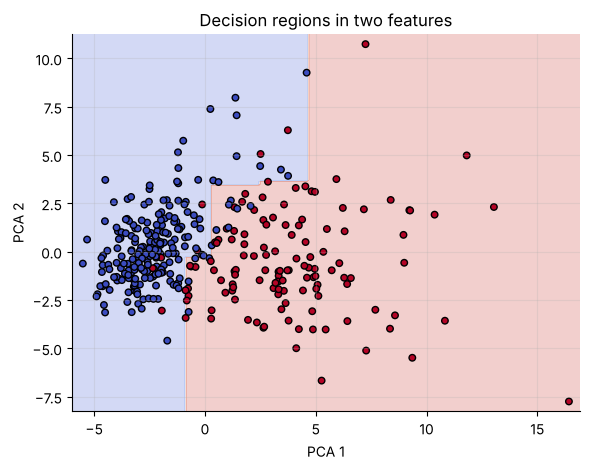

In [9]:
pred = final_model.predict(X_test)
labels = bundle.target_names or None
fig = viz.plot_confusion(y_test, pred, labels=labels)
save_figure(fig, NOTEBOOK_ID, "confusion"); plt.show()
if y_test.nunique() == 2:
    fig = viz.plot_roc_pr(final_model, X_test, y_test)
    save_figure(fig, NOTEBOOK_ID, "roc_pr"); plt.show()
fig = viz.plot_learning_curve(final_model, X_trainval, y_trainval, scoring=SCORING)
save_figure(fig, NOTEBOOK_ID, "learning_curve"); plt.show()
# decision regions in two PCA axes
pca_view = PCA(n_components=2, random_state=SEED).fit(Xtr)
model_for_plot = clone(final_model.named_steps["model"])
fig = viz.plot_decision_boundary(lambda: clone(model_for_plot), pca_view.transform(Xtr), y_train.values,
                                 names=["PCA 1", "PCA 2"])
save_figure(fig, NOTEBOOK_ID, "decision_regions"); plt.show()

## 12. Interpretation

Permutation importance shows which inputs the model relies on. The confusion matrix shows which classes are mixed up, and the list of misclassified rows is the starting point for error analysis. A model is only as good as the cases it fails on.

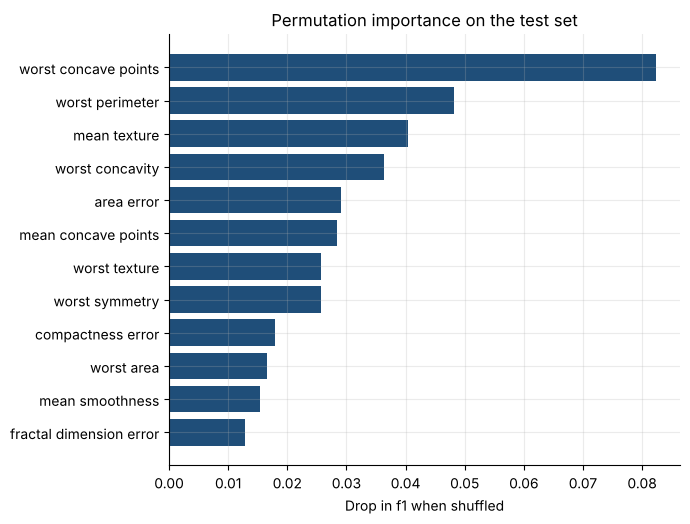

Top features: worst concave points, worst perimeter, mean texture, worst concavity, area error
Misclassified test rows: 2 of 114

Test F1: 0.9756 | baseline F1: 0.0000
Cross validation spread (std): 0.0193. A test gap larger than this spread is meaningful.


In [10]:
perm = permutation_importance(final_model, X_test, y_test, scoring=SCORING, n_repeats=10, random_state=SEED)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
fig = viz.plot_importance(importance.index, importance.values, title="Permutation importance on the test set",
                          top=12, xlabel="Drop in " + SCORING + " when shuffled")
save_figure(fig, NOTEBOOK_ID, "importance"); plt.show()
print("Top features:", ", ".join(importance.index[:5]))
errors = (y_test.values - final_model.predict(X_test)) if TASK == "regression" else (y_test.values != final_model.predict(X_test))
if TASK == "regression":
    worst = pd.DataFrame({"actual": y_test.values, "predicted": final_model.predict(X_test)}, index=y_test.index)
    worst["abs_error"] = (worst["actual"] - worst["predicted"]).abs()
    print("Largest test errors:")
    display(worst.sort_values("abs_error", ascending=False).head(5).round(3))
else:
    print("Misclassified test rows:", int(errors.sum()), "of", len(errors))
print()
print(f"Test {SELECT}: {test_metrics[SELECT]:.4f} | baseline {SELECT}: {baseline_metrics[SELECT]:.4f}")
print(f"Cross validation spread (std): {cv_scores.std(ddof=1):.4f}. A test gap larger than this spread is meaningful.")

## 13. Experiments and Challenges

### Experiment 1: Error against number of rounds

Staged accuracy on training and validation rows.

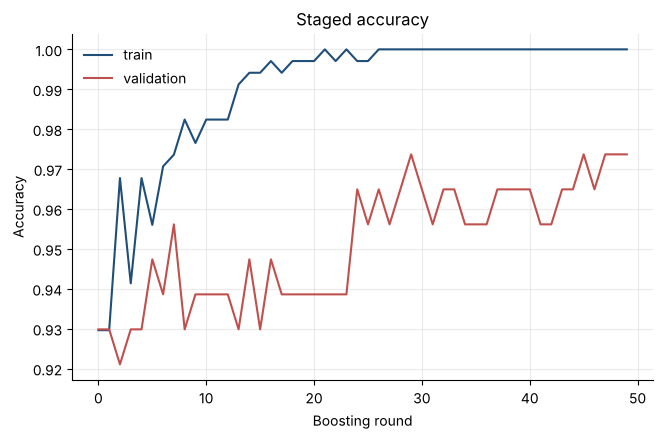

In [11]:
ada = clone(final_model.named_steps["model"]).fit(Xtr, y_train)
tr = list(ada.staged_score(Xtr, y_train)); va = list(ada.staged_score(Xva, y_val))
plt.plot(tr, label="train"); plt.plot(va, label="validation"); plt.xlabel("Boosting round"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Staged accuracy"); plt.show()

### Experiment 2: Label noise

Flip 10 percent of training labels and test on clean validation labels. AdaBoost versus a random forest.

In [12]:
from sklearn.ensemble import RandomForestClassifier
rng = np.random.default_rng(SEED)
flip = rng.random(len(y_train)) < 0.10
y_noisy = np.where(flip, 1 - y_train.values, y_train.values)
for name, m in [("AdaBoost", AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=200, random_state=SEED)), ("Random forest", RandomForestClassifier(n_estimators=200, random_state=SEED))]:
    clean = clone(m).fit(Xtr, y_train).score(Xva, y_val)
    noisy = clone(m).fit(Xtr, y_noisy).score(Xva, y_val)
    print(f"{name}: validation accuracy clean labels {clean:.3f}, 10% flipped labels {noisy:.3f}")

AdaBoost: validation accuracy clean labels 0.965, 10% flipped labels 0.912


Random forest: validation accuracy clean labels 0.974, 10% flipped labels 0.965


### Experiment 3: Weak learner depth

Stumps versus depth 3 trees.

In [13]:
from sklearn.model_selection import cross_val_score
for depth in [1, 2, 3]:
    s = cross_val_score(make_model_pipeline(X_trainval, AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=depth), n_estimators=100, random_state=SEED)), X_trainval, y_trainval, cv=5, scoring="f1")
    print(f"depth {depth}: CV F1 {s.mean():.3f} +- {s.std(ddof=1):.3f}")

depth 1: CV F1 0.955 +- 0.010


depth 2: CV F1 0.955 +- 0.018


depth 3: CV F1 0.964 +- 0.018


### Exercises for learners

1. Repeat the notebook with `SEED = 7` and report how much the headline metric changes.
2. Change the metric used for model choice and see whether the chosen value changes.
3. Replace the validation sweep with `GridSearchCV` and compare the chosen value.

## 14. Research Discussion

Freund and Schapire show that training error falls quickly with rounds and give generalisation bounds. Our staged accuracy plot shows the empirical side on a different dataset. The noise experiment tests the commonly cited weakness to label noise on this data only.

**Dataset and method differences.** The papers above use other datasets, other splits and often other implementations. We do not claim that our numbers agree or disagree with them. What this notebook can show is whether the behaviour described in the paper (for example the effect of a parameter) appears on our data.

**Possible improvements.** Compare with gradient boosting under the same splits, use early stopping, and try the SAMME.R style real boosting where available.

**Research limitations.** One dataset, one split seed for the headline number, and small test sets for the UCI data. Cross validation spread is reported to show how unstable a single split can be.

## 15. Summary and Further Reading

**Key takeaways**

- Boosting reweights hard rows.
- Stumps are enough weak learners.
- Label noise hurts exponential loss.

**Use cases.** Small clean datasets, feature selection with stumps.

**Limitations.** Sensitive to noisy labels.

**Recommended next notebook.** Extra Trees.

**Further reading.** See `references.md` in this folder and the library documentation for the classes used above.